# §5.2 — Viscosidades e tensão superficial (Figuras 19–21, Tabela 12)

Correlações de Pedersen (vapor), Allan & Teja (líquido) e Brock & Bird (tensão) nos 159 pontos
da Figura 13, comparadas por distribuição (Q–Q) com os dois eixos das paridades digitalizadas:
o HYSYS (eixo y, a referência) e a implementação da dissertação (eixo x). Não há correspondência
ponto a ponto, e os marcadores sobrepostos fundem-se na digitalização (a Figura 20 tem 24
marcadores para 159 pontos), pelo que os nossos valores são fundidos da mesma maneira antes de
comparar (`merge_like_figure`). Não simula.

In [1]:
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from dissertation.notebook_utils import figure, make_fluid, plt, qq_parity, save, table

from cmfsim.thermo import FlashOptions, phase_state
from cmfsim.thermo.viscosity import allan_teja_viscosity

cs, z = make_fluid("table6_validation")
f13 = figure(13)
pts_T, pts_P = f13["series"]["Pontos analisados (P,T)"]
# o eixo de temperatura da Figura 13 está em kelvin (os pontos vão de ~130 a ~530 K); a versão
# anterior deste notebook somava 273,15 e punha 155 dos 159 pontos fora do envelope
T_is_kelvin = pts_T.max() > 400.0
T = pts_T if T_is_kelvin else pts_T + 273.15
P = pts_P * 1e5
st = phase_state(T, P, z, cs, FlashOptions(stability_test=True))
two = st.two_phase > 0
print(f"{T.size} pontos, {int(two.sum())} bifásicos; T de {T.min():.0f} a {T.max():.0f} K")
table(
    [
        (
            "viscosidade do vapor (Pa s)",
            f"{np.median(st.mu_V[two]):.2e}",
            f"{st.mu_V[two].min():.2e}",
            f"{st.mu_V[two].max():.2e}",
        ),
        (
            "viscosidade do líquido (Pa s)",
            f"{np.median(st.mu_L[two]):.2e}",
            f"{st.mu_L[two].min():.2e}",
            f"{st.mu_L[two].max():.2e}",
        ),
        (
            "tensão superficial (N/m)",
            f"{np.median(st.sigma[two]):.4f}",
            f"{st.sigma[two].min():.4f}",
            f"{st.sigma[two].max():.4f}",
        ),
    ],
    ["propriedade", "mediana", "mín", "máx"],
)

159 pontos, 159 bifásicos; T de 137 a 516 K
| propriedade | mediana | mín | máx |
|---|---|---|---|
| viscosidade do vapor (Pa s) | 1.44e-05 | 5.53e-06 | 2.12e-05 |
| viscosidade do líquido (Pa s) | 1.75e-04 | 8.96e-05 | 9.41e-03 |
| tensão superficial (N/m) | 0.0100 | 0.0017 | 0.0317 |


## Figuras 19–21 por quantis (eixos das figuras em Pa·s e N/m, sem reescala)

figura: notebooks/figs/nb_5_2_fig19_21_qq.png


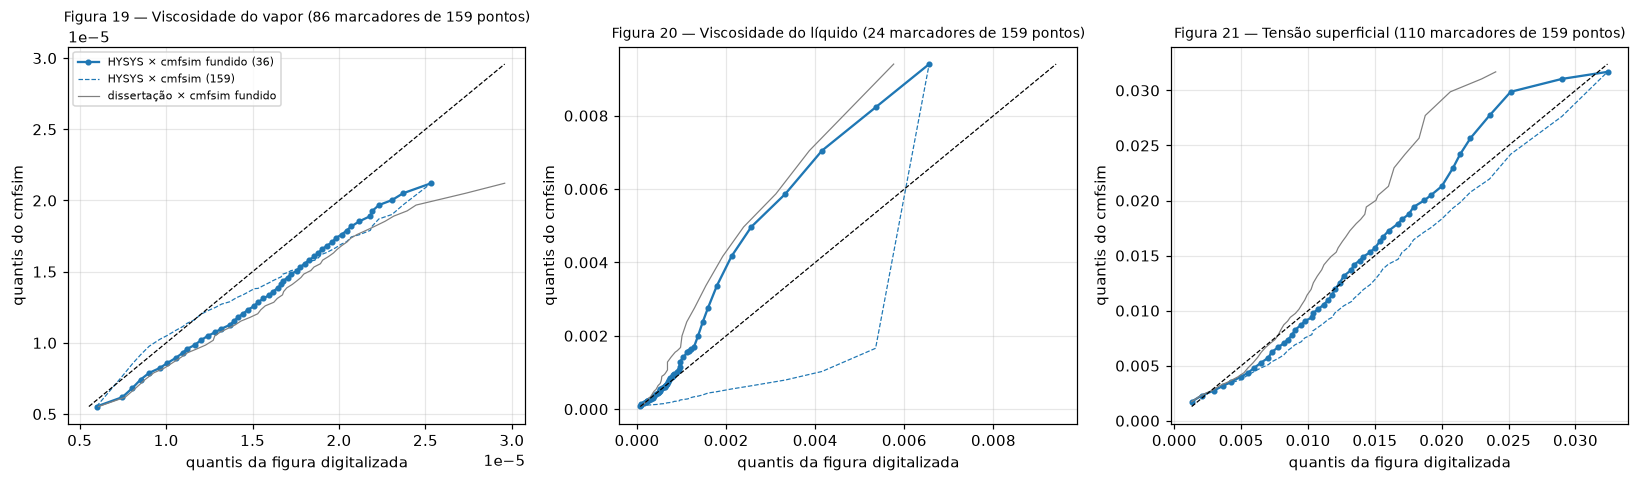

| figura | marcadores na figura | cmfsim fundido | mediana fundida / HYSYS | mediana crua / HYSYS |
|---|---|---|---|---|
| Figura 19 (μ_V) | 86 | 36 | 0.841 | 0.885 |
| Figura 20 (μ_L) | 24 | 16 | 1.107 | 0.251 |
| Figura 21 (σ) | 110 | 53 | 1.011 | 0.827 |
Tabela 12 (dissertação × HYSYS): R² 0,941 (vapor), 0,964 (líquido), 0,863 (tensão); sem os valores emparelhados do HYSYS não há R² equivalente aqui.


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ratios = []
for ax, (n, mine, lab) in zip(axes, ((19, st.mu_V, "μ_V"), (20, st.mu_L, "μ_L"), (21, st.sigma, "σ"))):
    rm, rr, n_fig, n_m = qq_parity(ax, figure(n), mine[two], int(two.sum()))
    ratios.append((f"Figura {n} ({lab})", n_fig, n_m, f"{rm:.3f}", f"{rr:.3f}"))
axes[0].legend(fontsize=7)
fig.tight_layout()
save(fig, "nb_5_2_fig19_21_qq")
table(
    ratios,
    ["figura", "marcadores na figura", "cmfsim fundido", "mediana fundida / HYSYS", "mediana crua / HYSYS"],
)
print(
    "Tabela 12 (dissertação × HYSYS): R² 0,941 (vapor), 0,964 (líquido), 0,863 (tensão); sem os valores emparelhados do HYSYS não há R² equivalente aqui."
)

## Viscosidade do líquido: a regra de mistura de Allan & Teja (issue 008)

Crua, a nossa distribuição de μ_L parece 3–4× abaixo do HYSYS e da dissertação (medianas 0,18
contra 0,70 e 0,54 mPa·s). É um artefacto: os 159 valores concentram-se em 0,1–0,3 mPa·s, que na
escala da Figura 20 (0–6 mPa·s em 1013 px) são 17–50 px, e fundem-se em meia dúzia de marcadores;
fundidos como a figura, os nossos valores dão 15–25 marcadores (a figura tem 24) com mediana
0,57–0,73 mPa·s, igual à do HYSYS. A formulação impressa na dissertação (pp. 83–84, eqs.
137–141: Nc_m = Σ x_i Nc_i, os mesmos A, B, C e a mesma exponencial) é a que implementámos, e o
nC8 puro a 300 K dá 0,50 mPa·s (medido 0,51). Para registo, as regras de mistura alternativas
nos mesmos 159 estados (sem fusão):

In [3]:
f20 = figure(20)
_, (xd20, yd20) = next(iter(f20["series"].items()))
x_L = st.x[two]
MW = np.asarray(cs.MW)
Nc_i = np.asarray(cs.Nc_eff)
w_L = x_L * MW / (x_L * MW).sum(axis=1, keepdims=True)


def allan_teja_Nc(T, Nc):
    A = 145.73 + 99.01 * Nc + 0.83 * Nc**2 - 0.125 * Nc**3
    B = 30.48 + 34.01 * Nc - 1.23 * Nc**2 + 0.017 * Nc**3
    C = -3.07 - 1.99 * Nc
    return np.exp(A * (1.0 / (T + C) - 1.0 / B)) * 1e-3


def q5(a):
    return [f"{v*1e3:.3f}" for v in np.quantile(a, [0.05, 0.25, 0.5, 0.75, 0.95])]


rows = [
    ("HYSYS (eixo y da Figura 20)", *q5(yd20)),
    ("dissertação (eixo x)", *q5(xd20)),
    ("cmfsim: Nc médio molar (atual)", *q5(allan_teja_Nc(T[two], x_L @ Nc_i))),
    ("Nc médio mássico", *q5(allan_teja_Nc(T[two], w_L @ Nc_i))),
    (
        "ln μ médio molar dos puros",
        *q5(np.exp(np.sum(x_L * np.log(np.stack([allan_teja_Nc(T[two], n) for n in Nc_i], 1)), 1))),
    ),
]
table(rows, ["μ_L [mPa s]", "q05", "q25", "q50", "q75", "q95"])
i8 = list(cs.names).index("nC8")
e8 = np.zeros((1, cs.n))
e8[0, i8] = 1.0
print(f"controlo: nC8 puro a 300 K = {1e3*allan_teja_viscosity(np.array([300.0]), e8, cs)[0]:.3f} mPa s (medido 0,51)")

| μ_L [mPa s] | q05 | q25 | q50 | q75 | q95 |
|---|---|---|---|---|---|
| HYSYS (eixo y da Figura 20) | 0.116 | 0.442 | 0.699 | 1.165 | 3.749 |
| dissertação (eixo x) | 0.160 | 0.341 | 0.540 | 0.894 | 3.513 |
| cmfsim: Nc médio molar (atual) | 0.100 | 0.128 | 0.175 | 0.292 | 0.891 |
| Nc médio mássico | 0.122 | 0.158 | 0.226 | 0.397 | 1.640 |
| ln μ médio molar dos puros | 0.087 | 0.115 | 0.158 | 0.262 | 0.809 |
controlo: nC8 puro a 300 K = 0.503 mPa s (medido 0,51)


Lição de método: um Q–Q contra marcadores digitalizados tem de simular a fusão dos marcadores,
senão qualquer propriedade concentrada em valores baixos parece "abaixo" da figura. A
sensibilidade do Apêndice A horizontal a μ_L (×3 sobe a mediana de 0,43× para 0,52×) fica na
issue 008 como informação, não como correção.